In [80]:
import numpy as np
import matplotlib.pyplot as plt
from keras.datasets import imdb
from keras.models import Sequential
from keras.layers import Embedding

In [81]:
from keras.layers import SimpleRNN
from keras.layers import Dense
from keras.layers import Input
from keras.preprocessing.sequence import pad_sequences

In [82]:
num_words = 10000
(x_train,y_train),(x_test,y_test) = imdb.load_data(num_words=num_words)

In [83]:
print(x_train[0])

[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 19, 178, 32]


In [84]:
maxlen = 500
x_train = pad_sequences(x_train, maxlen = maxlen)
x_test = pad_sequences(x_test, maxlen = maxlen)

In [85]:
model = Sequential()
model.add(Input(shape=(maxlen,)))


In [86]:
model.add(Embedding(input_dim = 10000,
                    output_dim =32,
                    input_length = maxlen))

In [87]:
model.add(SimpleRNN(32))

In [88]:
model.add(Dense(1,activation ='sigmoid'))

In [93]:
model.compile(optimizer = 'adam',
              loss = 'binary_crossentropy',
              metrics = ['accuracy'])

In [94]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, 500, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_3 (SimpleRNN)        │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 322,113 (1.23 MB)

 Trainable params: 322,113 (1.23 MB)

 Non-trainable params: 0 (0.00 B)

In [95]:
x_val = x_train[:1000]
partial_x_train =x_train[1000:]
y_val = y_train[:1000]
partial_y_train = y_train[1000:]

In [96]:
history = model.fit(x_train,
y_train,
epochs=20,
batch_size=64,
validation_split=0.2)

Epoch 1/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 72s 201ms/step - accuracy: 0.5576 - loss: 0.6782 - val_accuracy: 0.5862 - val_loss: 0.6597
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 65s 148ms/step - accuracy: 0.7448 - loss: 0.5374 - val_accuracy: 0.7458 - val_loss: 0.5226
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 78s 136ms/step - accuracy: 0.9187 - loss: 0.2214 - val_accuracy: 0.7750 - val_loss: 0.5528
Epoch 4/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 40s 126ms/step - accuracy: 0.9836 - loss: 0.0655 - val_accuracy: 0.7298 - val_loss: 0.7322
Epoch 5/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 42s 129ms/step - accuracy: 0.9962 - loss: 0.0200 - val_accuracy: 0.6876 - val_loss: 0.9206
Epoch 6/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 45s 141ms/step - accuracy: 0.9993 - loss: 0.0079 - val_accuracy: 0.7562 - val_loss: 0.8061
Epoch 7/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 81s 138ms/step - accuracy: 0.9998 - loss: 0.0024 - val_accuracy: 0.7764 - val_loss: 0.7799
Epoch 8/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 78s 127ms/step - accuracy: 0.9999 - loss: 0

In [97]:
loss, accuracy = model.evaluate(x_test,y_test)
print("test accuracy:", accuracy)

782/782 ━━━━━━━━━━━━━━━━━━━━ 25s 32ms/step - accuracy: 0.7728 - loss: 1.1354
test accuracy: 0.7728400230407715


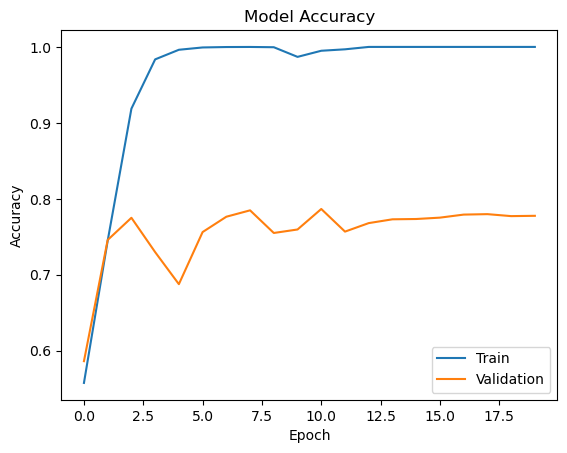

In [100]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])
plt.show()

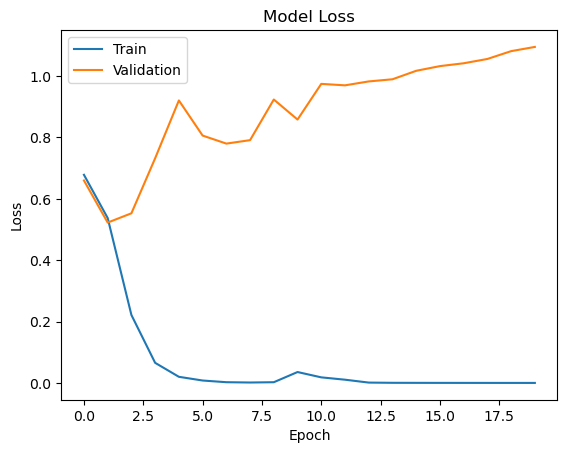

In [101]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'])
plt.show()
